# Voorspel herseninfarct

##### groepnaam: Groep 7 (RSR)



##### namen: Resham Anwar (25141511), Sharina Nasrullah (25103083), Rishano Narraina (25113011)
##### Kaggle usernames: Resham Anwar, SharinaHHS, 

## libraries importeren

In [121]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## datasets importeren

### train data

In [122]:
train= pd.read_csv('train.csv')
train

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33545,71911,9.0,0,0,109.80,14.5,False,True,False,True,...,False,False,False,True,True,False,False,False,False,0
33546,19648,47.0,0,0,88.61,30.8,True,False,False,False,...,False,True,False,False,False,True,False,False,False,0
33547,35550,3.0,0,0,89.68,16.2,True,False,False,True,...,False,False,False,True,True,False,False,False,False,0
33548,65453,56.0,1,0,82.44,27.8,True,False,False,False,...,False,False,False,False,False,True,False,False,True,0


### test data

In [123]:
test= pd.read_csv('test.csv')
test

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,32840,52.0,0,0,97.32,21.8,True,False,False,False,...,False,False,True,False,False,False,True,False,False,True
1,45158,30.0,0,0,227.99,47.7,True,False,False,False,...,False,False,True,False,False,False,True,False,False,True
2,56105,26.0,0,0,113.28,24.4,True,False,False,False,...,False,False,True,False,False,False,True,False,True,False
3,3112,24.0,0,0,79.15,21.0,True,False,False,False,...,False,False,True,False,False,False,True,True,False,False
4,35224,63.0,0,0,89.69,33.3,True,False,False,False,...,False,False,True,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8383,60672,24.0,0,0,77.54,25.0,True,False,False,True,...,False,False,True,False,False,True,False,False,True,False
8384,25989,17.0,0,0,99.99,22.7,True,False,False,True,...,False,False,False,True,False,True,False,False,True,False
8385,34072,11.0,0,0,80.11,22.2,True,False,False,True,...,False,False,False,False,True,False,True,False,False,False
8386,32400,16.0,0,0,105.26,47.5,True,False,False,True,...,False,False,True,False,False,True,False,False,True,False


### sample data

In [124]:
sample= pd.read_csv('sample_submission.csv')
sample

,id,stroke
0,32840,1
1,45158,0
2,56105,1
3,3112,0
4,35224,1
...,...,...
8383,60672,0
8384,25989,0
8385,34072,1
8386,32400,0


## 1. Data begrijpen & Exploratieve Data Analyse 

### 1.1 beschrijving van de variabelen

| kolom | uileg | type |
|-------|-------|------|
| id    | unieke identificatie van de patiënt | numeriek |
| age   | leeftijd van de patiënt | numeriek |
| hypertension | Geeft aan of de patiënt hypertensie (hoge bloeddruk) heeft. 0 = nee, 1 = ja | numeriek (binair) |
| heart_disease | Geeft aan of de patiënt hartaandoening heeft: 0 = nee, 1 = ja | numeriek (binair) |
| avg_glucose_level| gemiddelde glucosegehalte van de patiënt | numeriek |
| bmi | Body Mass Index van de patiënt| numeriek |
| gender_Female | geeft aan of de patiënt een vrouw is. False = nee, True = ja | numeriek (binair) |
| gender_Male | geeft aan of de patiënt een man is. False = nee, True = ja | numeriek (binair) |
| gender_Other | geeft aan of de patiënt onder de categorie "other" valt. False = nee, True = ja | numeriek (binair) |
| ever_married_no | geeft aan of de patiënt nooit is getrouwd. False = nee, True = ja | numeriek (binair) |
| ever_married_Yes | geeft aan of de patiënt ooit is getrouwd. False = nee, True = ja | numeriek (binair) |
| work_type_Govt_job | geeft aan of de patiënt een overheidsbaan heeft. False = nee, True = ja | numeriek (binair) |
| work_type_Never_worked | geeft aan of de patiënt nooit heeft gewerkt. False = nee, True = ja | numeriek (binair) |
| work_type_Private | geeft aan of de patiënt in de private sector heeft gewerkt. False = nee, True = ja | numeriek (binair) |
| work_type_Self-employed | geeft aan of de patiënt zelfstandig ondernemer is. False = nee, True = ja | numeriek (binair) |
| work_type_children |                                                                           | numeriek (binair) |
| Residence_type_Rural | geeft aan of de patiënt in een landelijke gebied woont. False = nee, True = ja | numeriek (binair) |
| Residence_type_Urban | geeft aan of de patiënt in een stedelijke gebied woont. False = nee, True = ja | numeriek (binair) |
| smoking_status_formerly smoked | geeft aan of de patiënt vroeger rookte. False = nee, True = ja | numeriek (binair) |
| smoking_status_never smoked | geeft aan dat de patiënt nooit heeft gerookt. False = nee, True = ja | numeriek (binair) |
| smoking_status_smokes | geeft aan dat de patiënt rookt. False = nee, True = ja | numeriek (binair) |
| stroke | doelvariabele. geeft aan of de patiënt een stroke heeft gehad | numeriek (binair) |

### 1.2 Data exploren

In [125]:
display(train.describe())
train.info()
display(train.dtypes)
display(train.isna().sum())
display(np.min(train['age']))
display(np.max(train['age']))

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000


<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          33550 non-n

id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                        bool
gender_Male                          bool
gender_Other                         bool
ever_married_No                      bool
ever_married_Yes                     bool
work_type_Govt_job                   bool
work_type_Never_worked               bool
work_type_Private                    bool
work_type_Self-employed              bool
work_type_children                   bool
Residence_type_Rural                 bool
Residence_type_Urban                 bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
stroke                              int64
dtype: object

id                                0
age                               0
hypertension                      0
heart_disease                     0
avg_glucose_level                 0
bmi                               0
gender_Female                     0
gender_Male                       0
gender_Other                      0
ever_married_No                   0
ever_married_Yes                  0
work_type_Govt_job                0
work_type_Never_worked            0
work_type_Private                 0
work_type_Self-employed           0
work_type_children                0
Residence_type_Rural              0
Residence_type_Urban              0
smoking_status_formerly smoked    0
smoking_status_never smoked       0
smoking_status_smokes             0
stroke                            0
dtype: int64

np.float64(0.08)

np.float64(82.0)

### 1.3 Data splitsing en controle

In [126]:
X= train.drop(columns= 'stroke')
y= train['stroke']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (33550, 21)
y shape: (33550,)


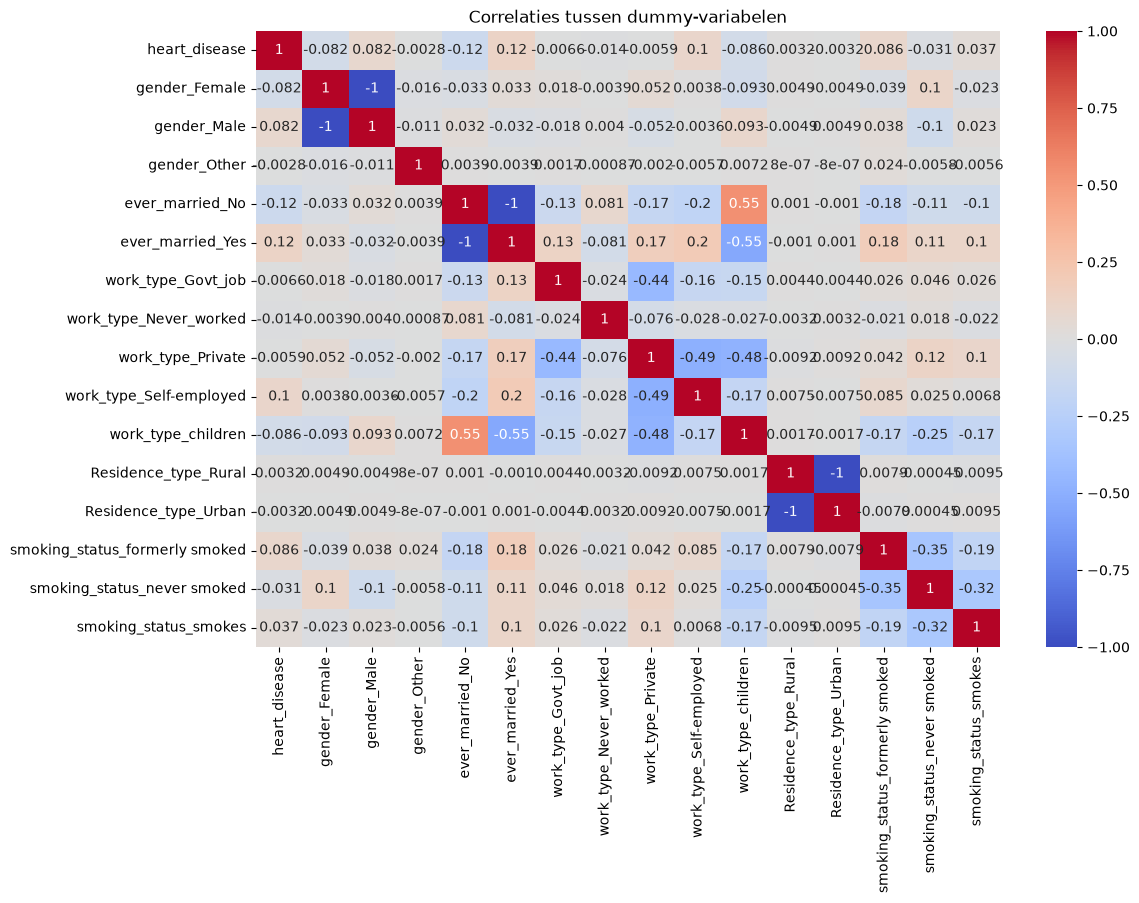

In [127]:
dummy_cols = [
    col for col in train.columns 
    if "_" in col and col not in ["avg_glucose_level", "bmi"]
]

plt.figure(figsize=(12, 8))
sns.heatmap(train[dummy_cols].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlaties tussen dummy-variabelen")
plt.show()

##### uit deze correlatiematrix blijkt dat dummy-variabelen binnen dezelfde categorie (zoals gender, work_type, smoking_status en residence_type) zeer sterke negatieve correlaties vertonen (tot -1.0) dit duidt op multicollineariteit, omdat deze variabelen samen één categorie representeren. Daarom gaan we per categorische variabele één dummy verwijderen om multicollineariteit te voorkomen

In [128]:
train= train.drop(columns= ['gender_Male', 'ever_married_No', 'Residence_type_Urban', 'work_type_Private', 'smoking_status_never smoked'])


In [129]:
train

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Other,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Self-employed,work_type_children,Residence_type_Rural,smoking_status_formerly smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,False,False,False,False,False,False,True,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,True,False,False,True,False,True,False,False,0
2,26451,15.0,0,0,135.22,19.0,False,False,False,False,False,False,False,True,False,False,0
3,65210,47.0,0,0,64.89,28.2,False,False,True,False,False,True,False,False,False,False,0
4,69299,49.0,0,0,222.34,28.8,False,False,True,False,False,True,False,True,True,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33545,71911,9.0,0,0,109.80,14.5,False,False,False,False,False,False,True,True,False,False,0
33546,19648,47.0,0,0,88.61,30.8,True,False,True,False,False,False,False,False,False,False,0
33547,35550,3.0,0,0,89.68,16.2,True,False,False,False,False,False,True,True,False,False,0
33548,65453,56.0,1,0,82.44,27.8,True,False,True,True,False,False,False,False,False,True,0


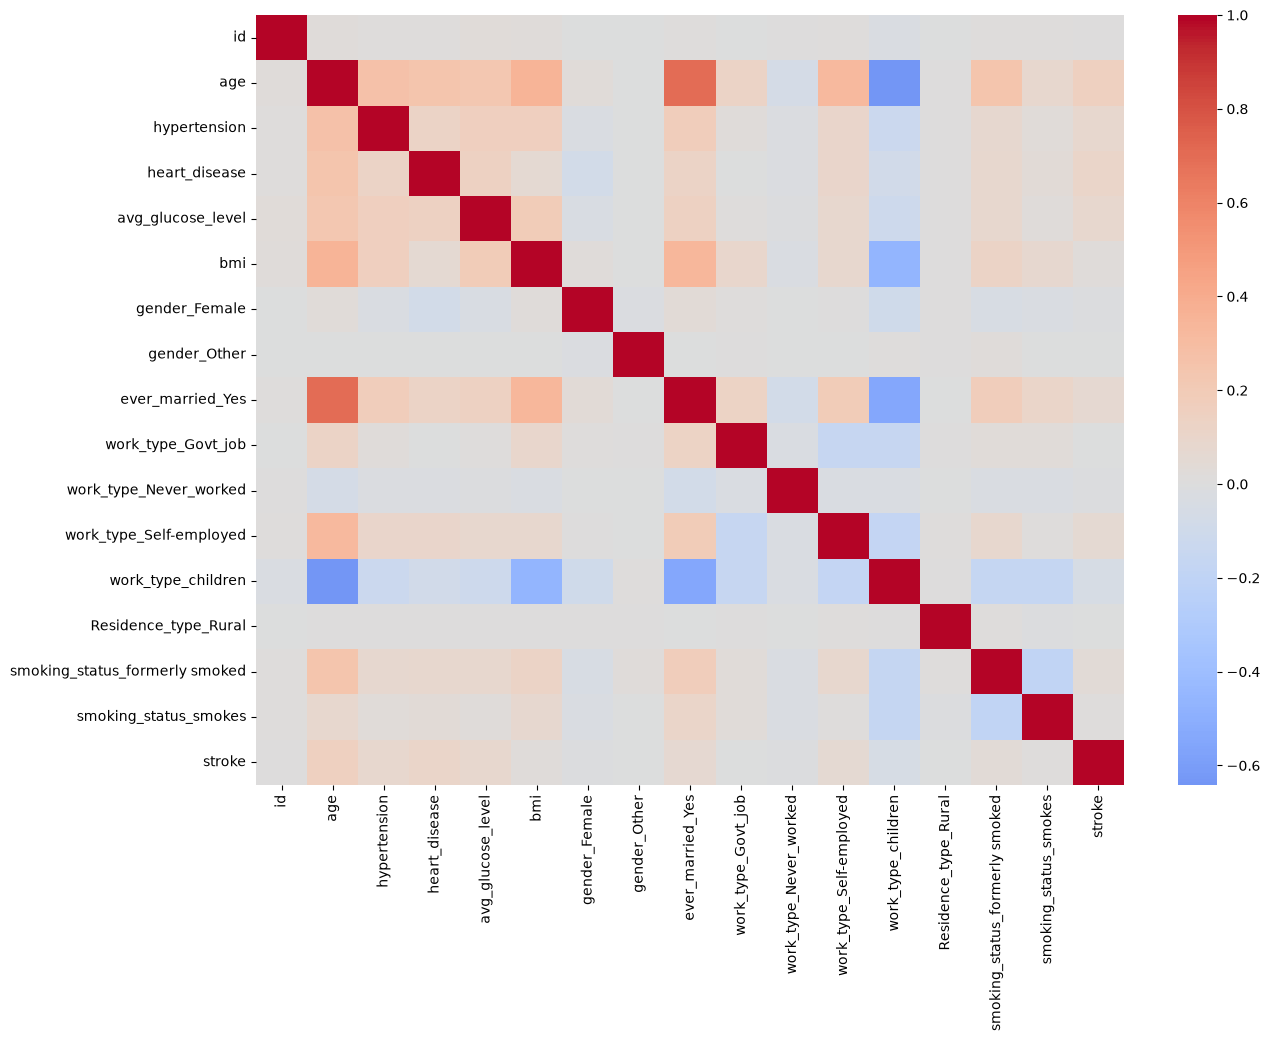

In [140]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))
sns.heatmap(train.corr(), cmap="coolwarm", center=0)
plt.show()

In [130]:
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

print("Categorische kolommen:", list(categorical_cols))
print("Numerieke kolommen:", list(numerical_cols))



Categorische kolommen: []
Numerieke kolommen: ['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']


In [131]:
y.value_counts(normalize=True)

stroke
0    0.98459
1    0.01541
Name: proportion, dtype: float64

### 1.4 Relaties tussen onafhankelijke variabelen en afhankelijke variabele

<Axes: xlabel='stroke', ylabel='bmi'>

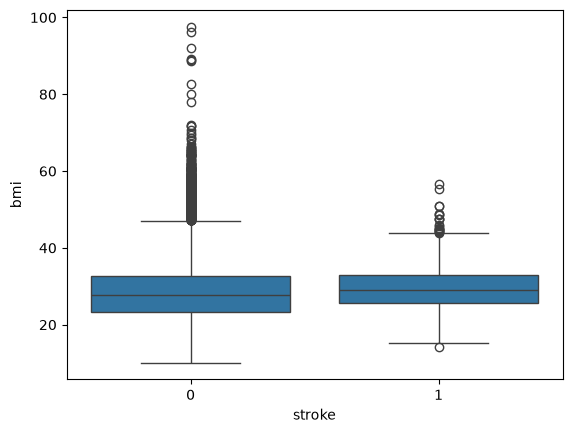

In [132]:
sns.boxplot(data= train, x='stroke', y= 'bmi')

uitleg

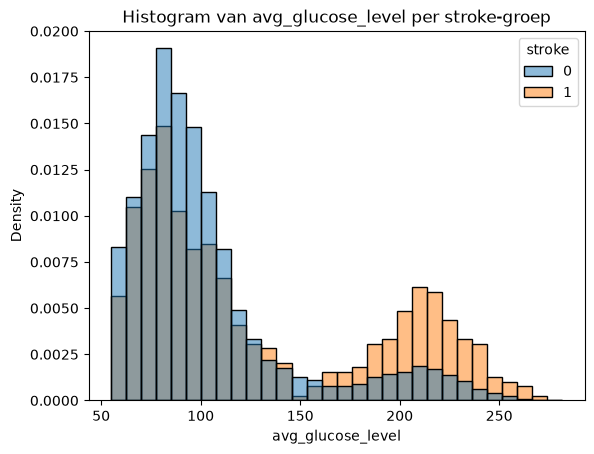

In [133]:
sns.histplot(data=train, x='avg_glucose_level', hue='stroke', kde= False, bins= 30, stat= "density", common_norm= False )
plt.title("Histogram van avg_glucose_level per stroke-groep")
plt.show()

uitleg

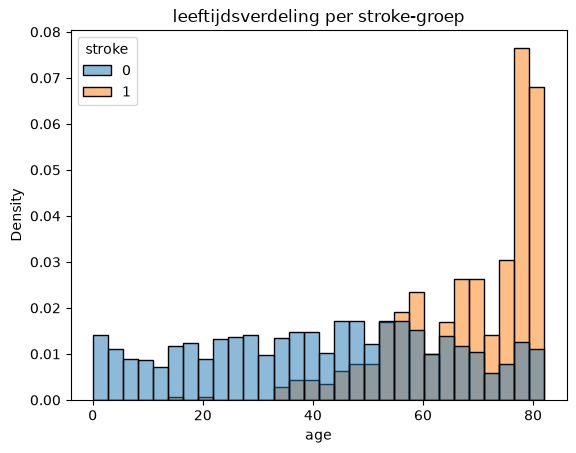

In [134]:
sns.histplot(data=train, x='age', hue='stroke', kde= False, bins= 30, stat= "density", common_norm= False )
plt.title("leeftijdsverdeling per stroke-groep")
plt.show()

uitleg

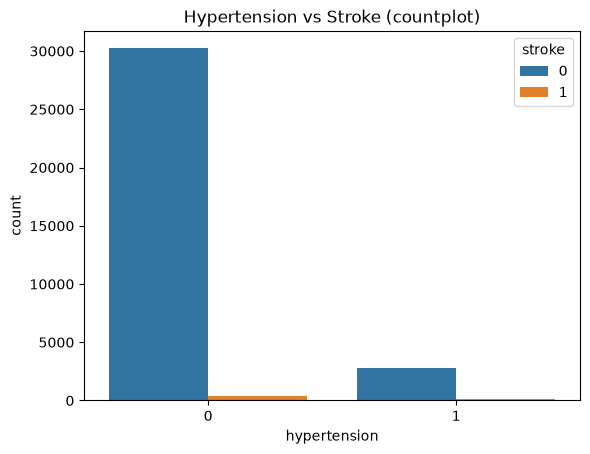

In [135]:
sns.countplot(data=train, x="hypertension", hue="stroke")
plt.title("Hypertension vs Stroke (countplot)")
plt.show()

uitleg

In [136]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test= train_test_split(X, y, test_size= 0.2, random_state= 42, stratify= y)